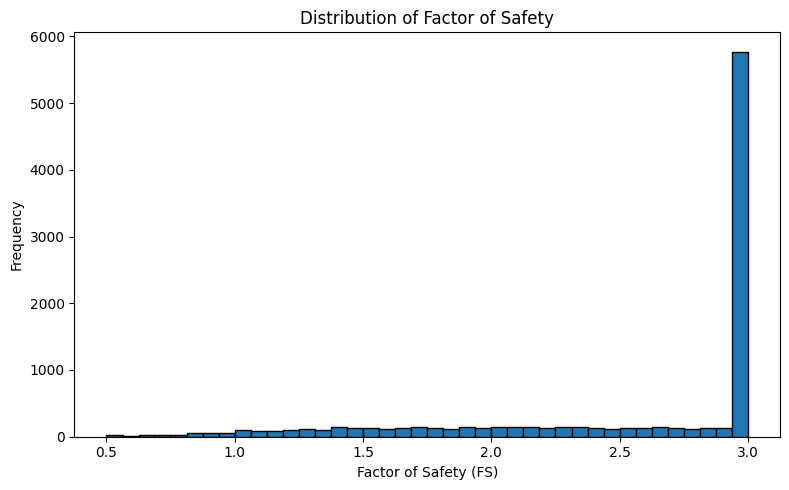

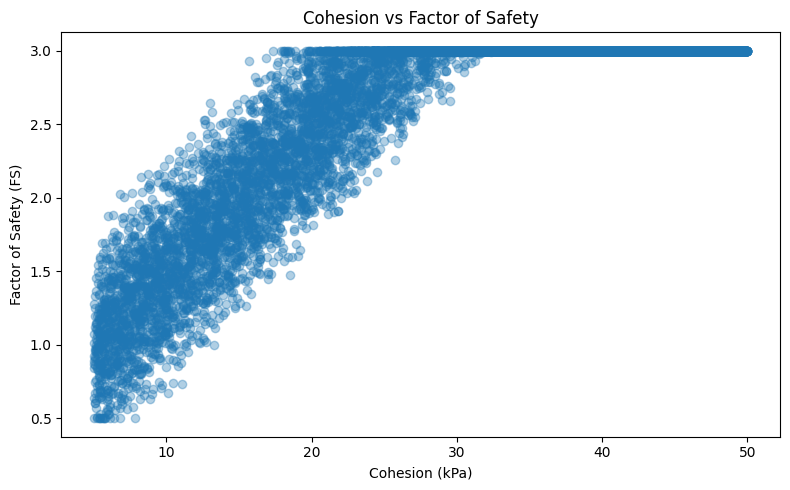

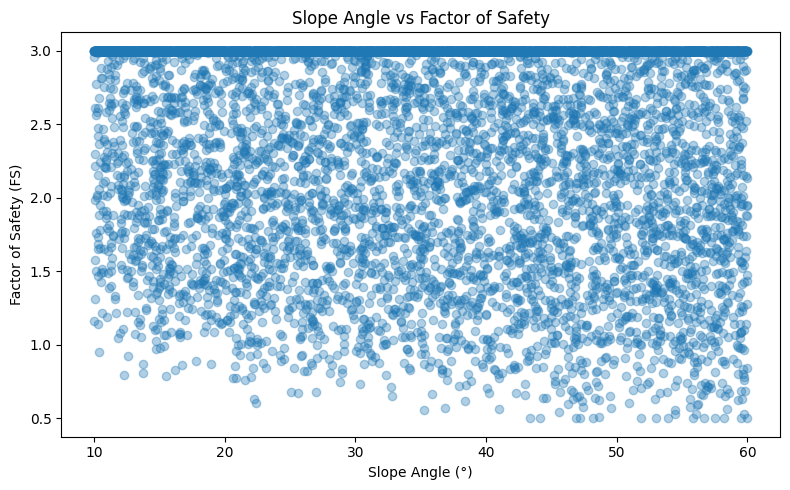

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("slope_stability_dataset.csv")

plt.figure(figsize=(8, 5))
plt.hist(df["Factor of Safety (FS)"], bins=40, edgecolor="black")
plt.xlabel("Factor of Safety (FS)")
plt.ylabel("Frequency")
plt.title("Distribution of Factor of Safety")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.scatter(
    df["Cohesion (kPa)"],
    df["Factor of Safety (FS)"],
    alpha=0.35
)
plt.xlabel("Cohesion (kPa)")
plt.ylabel("Factor of Safety (FS)")
plt.title("Cohesion vs Factor of Safety")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.scatter(
    df["Slope Angle (°)"],
    df["Factor of Safety (FS)"],
    alpha=0.35
)
plt.xlabel("Slope Angle (°)")
plt.ylabel("Factor of Safety (FS)")
plt.title("Slope Angle vs Factor of Safety")
plt.tight_layout()
plt.show()


In [ ]:

import pandas as pd
import numpy as np

df = pd.read_csv("slope_stability_dataset.csv")

target = "Factor of Safety (FS)"

print("Dataset shape:", df.shape)
print("\nFactor of Safety summary:")
print(df[target].describe())

print("\nMost frequent FS values:")
print(df[target].value_counts().head(10))

print("\nProportion at upper boundary:")
print((df[target] == 3.0).mean() * 100, "%")

print("\nProportion at lower boundary:")
print((df[target] == 0.5).mean() * 100, "%")

print("\nUnique FS values:", df[target].nunique())

print("\nInput feature ranges:")
print(df.describe().T)


Dataset shape: (10000, 9)

Factor of Safety summary:
count    10000.000000
mean         2.545083
std          0.659996
min          0.500000
25%          2.125824
50%          3.000000
75%          3.000000
max          3.000000
Name: Factor of Safety (FS), dtype: float64

Most frequent FS values:
Factor of Safety (FS)
3.000000    5635
0.500000      13
2.960807       1
1.414603       1
1.357672       1
2.917073       1
1.381975       1
1.742827       1
2.187722       1
2.362792       1
Name: count, dtype: int64

Proportion at upper boundary:
56.35 %

Proportion at lower boundary:
0.13 %

Unique FS values: 4354

Input feature ranges:
                               count       mean        std        min  \
Unit Weight (kN/m³)          10000.0  19.941596   2.876301  15.000116   
Cohesion (kPa)               10000.0  27.703844  13.018255   5.007099   
Internal Friction Angle (°)  10000.0  32.501260   7.169344  20.001203   
Slope Angle (°)              10000.0  34.935669  14.449730  10.0002

In [ ]:

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("slope_stability_dataset.csv")

feature_columns = [
    "Unit Weight (kN/m³)",
    "Cohesion (kPa)",
    "Internal Friction Angle (°)",
    "Slope Angle (°)",
    "Slope Height (m)",
    "Pore Water Pressure Ratio",
    "Reinforcement Type"
]

target_column = "Factor of Safety (FS)"

X = df[feature_columns].copy()
y = df[target_column].copy()

X = pd.get_dummies(
    X,
    columns=["Reinforcement Type"],
    dtype=int
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

numeric_columns = [
    "Unit Weight (kN/m³)",
    "Cohesion (kPa)",
    "Internal Friction Angle (°)",
    "Slope Angle (°)",
    "Slope Height (m)",
    "Pore Water Pressure Ratio"
]

scaler = StandardScaler()

X_train = X_train.copy()
X_test = X_test.copy()

X_train.loc[:, numeric_columns] = scaler.fit_transform(
    X_train[numeric_columns]
)

X_test.loc[:, numeric_columns] = scaler.transform(
    X_test[numeric_columns]
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)
print("Feature columns:", X_train.columns.tolist())


Training features: (8000, 10)
Testing features: (2000, 10)
Training targets: (8000,)
Testing targets: (2000,)
Feature columns: ['Unit Weight (kN/m³)', 'Cohesion (kPa)', 'Internal Friction Angle (°)', 'Slope Angle (°)', 'Slope Height (m)', 'Pore Water Pressure Ratio', 'Reinforcement Type_Drainage', 'Reinforcement Type_Geosynthetics', 'Reinforcement Type_Retaining Wall', 'Reinforcement Type_Soil Nailing']


In [ ]:

from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd
import numpy as np

models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    )
}

results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))


        Model    MAE   RMSE  R2 Score
Random Forest 0.0223 0.0411    0.9960
  Extra Trees 0.0155 0.0297    0.9979


In [ ]:

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

tf.keras.utils.set_random_seed(42)

dnn = keras.Sequential([
    keras.Input(shape=(X_train.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(1)
])

dnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True
)

history = dnn.fit(
    X_train.astype("float32"),
    y_train.astype("float32"),
    validation_split=0.2,
    epochs=200,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

y_pred_dnn = dnn.predict(
    X_test.astype("float32"),
    verbose=0
).ravel()

dnn_mae = mean_absolute_error(y_test, y_pred_dnn)
dnn_rmse = np.sqrt(mean_squared_error(y_test, y_pred_dnn))
dnn_r2 = r2_score(y_test, y_pred_dnn)

print("\nDNN Results")
print("MAE:", round(dnn_mae, 4))
print("RMSE:", round(dnn_rmse, 4))
print("R2 Score:", round(dnn_r2, 4))
print("Epochs completed:", len(history.history["loss"]))


Epoch 1/200
200/200 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 1.0320 - mae: 0.7262 - val_loss: 0.2297 - val_mae: 0.3940
Epoch 2/200
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1523 - mae: 0.3153 - val_loss: 0.0822 - val_mae: 0.2311
Epoch 3/200
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0357 - mae: 0.1482 - val_loss: 0.0171 - val_mae: 0.1039
Epoch 4/200
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0106 - mae: 0.0817 - val_loss: 0.0074 - val_mae: 0.0677
Epoch 5/200
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0058 - mae: 0.0601 - val_loss: 0.0048 - val_mae: 0.0541
Epoch 6/200
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0040 - mae: 0.0496 - val_loss: 0.0036 - val_mae: 0.0468
Epoch 7/200
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0030 - mae: 0.0431 - val_loss: 0.0030 - val_mae: 0.0423
Epoch 8/200
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0024 - mae: 0.0386 - val_loss: 0.0025 - val_mae: 0.0390
Epoch 9/200
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/

In [ ]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

y_true = np.asarray(y_test).reshape(-1)
y_pred = np.asarray(y_pred_dnn).reshape(-1)

evaluation = pd.DataFrame({
    "Actual FS": y_true,
    "Predicted FS": y_pred
})

evaluation["Absolute Error"] = abs(
    evaluation["Actual FS"] - evaluation["Predicted FS"]
)

groups = {
    "All test samples": np.ones(len(evaluation), dtype=bool),
    "FS below 3.0": evaluation["Actual FS"].to_numpy() < 3.0,
    "FS equal to 3.0": evaluation["Actual FS"].to_numpy() == 3.0,
    "Unstable samples (FS below 1.0)": evaluation["Actual FS"].to_numpy() < 1.0
}

rows = []

for name, mask in groups.items():
    subset = evaluation.loc[mask]

    if len(subset) == 0:
        continue

    rows.append({
        "Group": name,
        "Samples": len(subset),
        "MAE": mean_absolute_error(
            subset["Actual FS"], subset["Predicted FS"]
        ),
        "RMSE": np.sqrt(mean_squared_error(
            subset["Actual FS"], subset["Predicted FS"]
        )),
        "R2": (
            r2_score(subset["Actual FS"], subset["Predicted FS"])
            if len(subset) > 1 and subset["Actual FS"].nunique() > 1
            else np.nan
        )
    })

print(pd.DataFrame(rows).round(5).to_string(index=False))

print("\nDetailed error statistics:")
print(evaluation["Absolute Error"].describe().round(5))


                          Group  Samples     MAE    RMSE      R2
               All test samples     2000 0.00142 0.00297 0.99998
                   FS below 3.0      862 0.00200 0.00429 0.99995
                FS equal to 3.0     1138 0.00098 0.00127     NaN
Unstable samples (FS below 1.0)       56 0.00529 0.01456 0.98979

Detailed error statistics:
count    2000.00000
mean        0.00142
std         0.00261
min         0.00000
25%         0.00048
50%         0.00105
75%         0.00183
max         0.07663
Name: Absolute Error, dtype: float64


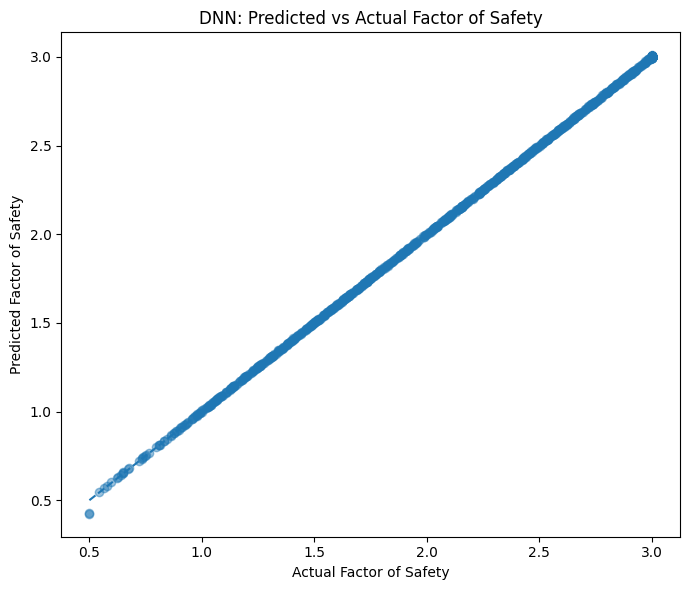

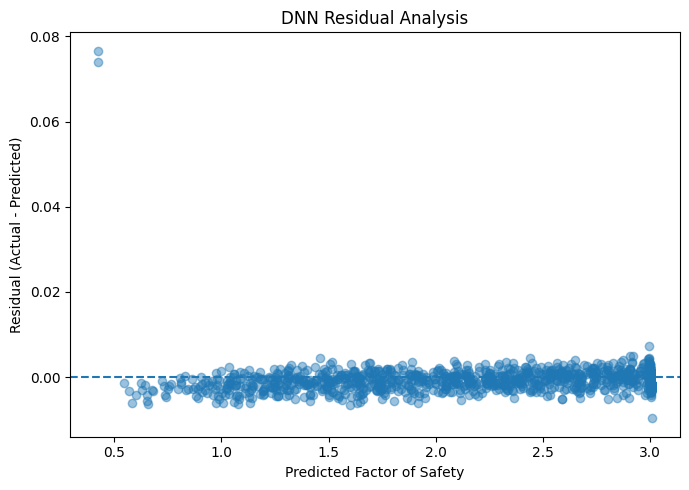

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))
plt.scatter(y_true, y_pred, alpha=0.45)

plt.plot(
    [0.5, 3.0],
    [0.5, 3.0],
    linestyle="--"
)

plt.xlabel("Actual Factor of Safety")
plt.ylabel("Predicted Factor of Safety")
plt.title("DNN: Predicted vs Actual Factor of Safety")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
residuals = y_true - y_pred

plt.scatter(y_pred, residuals, alpha=0.45)
plt.axhline(y=0, linestyle="--")
plt.xlabel("Predicted Factor of Safety")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("DNN Residual Analysis")
plt.tight_layout()
plt.show()


In [ ]:

import numpy as np
import pandas as pd

check = pd.DataFrame({
    "Actual FS": np.asarray(y_test).reshape(-1),
    "Predicted FS": np.asarray(y_pred_dnn).reshape(-1)
})

check["Absolute Error"] = abs(
    check["Actual FS"] - check["Predicted FS"]
)

print("Actual FS values at 3.0:")
print((check["Actual FS"] == 3.0).sum())

print("\nPredictions close to 3.0:")
print((check["Predicted FS"] >= 2.99).sum())

print("\nLargest prediction errors:")
print(
    check.sort_values("Absolute Error", ascending=False)
    .head(10)
    .round(5)
    .to_string(index=False)
)

print("\nPredictions outside the dataset's target range:")
print(
    check[
        (check["Predicted FS"] < 0.5) |
        (check["Predicted FS"] > 3.0)
    ].round(5).to_string(index=False)
)


Actual FS values at 3.0:
1138

Predictions close to 3.0:
1147

Largest prediction errors:
 Actual FS  Predicted FS  Absolute Error
   0.50000       0.42337         0.07663
   0.50000       0.42602         0.07398
   3.00000       3.00967         0.00967
   3.00000       2.99272         0.00728
   1.59570       1.60217         0.00647
   1.07043       1.07675         0.00632
   0.65128       0.65759         0.00631
   1.91303       1.91921         0.00617
   0.96966       0.97581         0.00614
   1.62857       1.63456         0.00599

Predictions outside the dataset's target range:
 Actual FS  Predicted FS  Absolute Error
       3.0       3.00098         0.00098
       3.0       3.00187         0.00187
       3.0       3.00186         0.00186
       3.0       3.00132         0.00132
       3.0       3.00104         0.00104
       3.0       3.00162         0.00162
       3.0       3.00117         0.00117
       3.0       3.00005         0.00005
       3.0       3.00010         0.00010


In [ ]:

# Inspect the two largest prediction errors
import numpy as np
import pandas as pd

y_true = np.asarray(y_test).reshape(-1)
y_pred = np.asarray(y_pred_dnn).reshape(-1)

error_check = pd.DataFrame(
    X_test,
    columns=X.columns
).reset_index(drop=True)

error_check["Actual FS"] = y_true
error_check["Predicted FS"] = y_pred
error_check["Absolute Error"] = abs(y_true - y_pred)

print(
    error_check.sort_values(
        "Absolute Error", ascending=False
    ).head(10).round(4).to_string(index=False)
)


 Unit Weight (kN/m³)  Cohesion (kPa)  Internal Friction Angle (°)  Slope Angle (°)  Slope Height (m)  Pore Water Pressure Ratio  Reinforcement Type_Drainage  Reinforcement Type_Geosynthetics  Reinforcement Type_Retaining Wall  Reinforcement Type_Soil Nailing  Actual FS  Predicted FS  Absolute Error
             -1.1141         -1.7335                      -1.0342           1.5589           -0.2255                     1.6697                            0                                 1                                  0                                0     0.5000        0.4234          0.0766
              0.2906         -1.7096                      -1.1590           1.2461           -0.1615                     1.6810                            0                                 1                                  0                                0     0.5000        0.4260          0.0740
              1.6513          1.5163                      -1.4236          -1.2936            1.5505

In [ ]:

import numpy as np
import pandas as pd

results = pd.DataFrame(
    X_test,
    columns=X.columns
).reset_index(drop=True)

results["Actual FS"] = np.asarray(y_test).reshape(-1)
results["Predicted FS"] = np.asarray(y_pred_dnn).reshape(-1)
results["Absolute Error"] = abs(
    results["Actual FS"] - results["Predicted FS"]
)

# Identify the reinforcement category from one-hot columns
reinforcement_columns = [
    column for column in results.columns
    if column.startswith("Reinforcement Type_")
]

results["Reinforcement"] = (
    results[reinforcement_columns]
    .idxmax(axis=1)
    .str.replace("Reinforcement Type_", "", regex=False)
)

# Focus on unstable samples
unstable = results[results["Actual FS"] < 1.0].copy()

print("Number of unstable test samples:", len(unstable))

print("\nError metrics by reinforcement type:")
summary = unstable.groupby("Reinforcement").agg(
    Samples=("Actual FS", "size"),
    Mean_Absolute_Error=("Absolute Error", "mean"),
    Maximum_Absolute_Error=("Absolute Error", "max"),
    Mean_Actual_FS=("Actual FS", "mean"),
    Mean_Predicted_FS=("Predicted FS", "mean")
)

print(summary.round(5).to_string())

print("\nUnstable samples with the largest errors:")
print(
    unstable.sort_values(
        "Absolute Error", ascending=False
    )[
        ["Reinforcement", "Actual FS",
         "Predicted FS", "Absolute Error"]
    ].head(10).round(5).to_string(index=False)
)


Number of unstable test samples: 56

Error metrics by reinforcement type:
                Samples  Mean_Absolute_Error  Maximum_Absolute_Error  Mean_Actual_FS  Mean_Predicted_FS
Reinforcement                                                                                          
Drainage             11              0.00220                 0.00429         0.81627            0.81847
Geosynthetics        10              0.01846                 0.07663         0.74469            0.73301
Retaining Wall       21              0.00251                 0.00631         0.85825            0.86072
Soil Nailing         14              0.00247                 0.00435         0.79607            0.79840

Unstable samples with the largest errors:
 Reinforcement  Actual FS  Predicted FS  Absolute Error
 Geosynthetics    0.50000       0.42337         0.07663
 Geosynthetics    0.50000       0.42602         0.07398
Retaining Wall    0.65128       0.65759         0.00631
 Geosynthetics    0.96966       0.9

In [ ]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

def evaluate_subset(X_part, y_part, predictions, split_name):
    result = pd.DataFrame(
        X_part, columns=X.columns
    ).reset_index(drop=True)

    result["Actual FS"] = np.asarray(y_part).reshape(-1)
    result["Predicted FS"] = np.asarray(predictions).reshape(-1)
    result["Absolute Error"] = abs(
        result["Actual FS"] - result["Predicted FS"]
    )

    reinforcement_cols = [
        c for c in result.columns
        if c.startswith("Reinforcement Type_")
    ]

    result["Reinforcement"] = (
        result[reinforcement_cols]
        .idxmax(axis=1)
        .str.replace("Reinforcement Type_", "", regex=False)
    )

    result = result[result["Actual FS"] < 1.0]

    summary = result.groupby("Reinforcement").agg(
        Samples=("Actual FS", "size"),
        MAE=("Absolute Error", "mean"),
        Maximum_Error=("Absolute Error", "max")
    )

    summary.insert(0, "Split", split_name)
    return summary

train_predictions = dnn.predict(
    X_train.astype("float32"), verbose=0
).ravel()

test_predictions = dnn.predict(
    X_test.astype("float32"), verbose=0
).ravel()

train_summary = evaluate_subset(
    X_train, y_train, train_predictions, "Training"
)

test_summary = evaluate_subset(
    X_test, y_test, test_predictions, "Testing"
)

print(
    pd.concat([train_summary, test_summary])
    .round(5)
    .to_string()
)


                   Split  Samples      MAE  Maximum_Error
Reinforcement                                            
Drainage        Training       56  0.00154        0.00401
Geosynthetics   Training       68  0.00556        0.02698
Retaining Wall  Training       51  0.00271        0.02612
Soil Nailing    Training       64  0.00323        0.04022
Drainage         Testing       11  0.00220        0.00429
Geosynthetics    Testing       10  0.01846        0.07663
Retaining Wall   Testing       21  0.00251        0.00631
Soil Nailing     Testing       14  0.00247        0.00435


In [ ]:

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("slope_stability_dataset.csv")

feature_columns = [
    "Unit Weight (kN/m³)",
    "Cohesion (kPa)",
    "Internal Friction Angle (°)",
    "Slope Angle (°)",
    "Slope Height (m)",
    "Pore Water Pressure Ratio",
    "Reinforcement Type"
]

target_column = "Factor of Safety (FS)"

X = df[feature_columns].copy()
y = df[target_column].copy()

# Convert reinforcement type into one-hot encoded features
X = pd.get_dummies(
    X,
    columns=["Reinforcement Type"],
    dtype=int
)

# 75:25 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42
)

# Standardize numerical features using training data only
numeric_columns = [
    "Unit Weight (kN/m³)",
    "Cohesion (kPa)",
    "Internal Friction Angle (°)",
    "Slope Angle (°)",
    "Slope Height (m)",
    "Pore Water Pressure Ratio"
]

scaler = StandardScaler()

X_train = X_train.copy()
X_test = X_test.copy()

X_train.loc[:, numeric_columns] = scaler.fit_transform(
    X_train[numeric_columns]
)

X_test.loc[:, numeric_columns] = scaler.transform(
    X_test[numeric_columns]
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)
print("Feature columns:", X_train.columns.tolist())


Training features: (7500, 10)
Testing features: (2500, 10)
Training targets: (7500,)
Testing targets: (2500,)
Feature columns: ['Unit Weight (kN/m³)', 'Cohesion (kPa)', 'Internal Friction Angle (°)', 'Slope Angle (°)', 'Slope Height (m)', 'Pore Water Pressure Ratio', 'Reinforcement Type_Drainage', 'Reinforcement Type_Geosynthetics', 'Reinforcement Type_Retaining Wall', 'Reinforcement Type_Soil Nailing']


In [ ]:

from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Random Forest
rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

# Extra Trees
et_model = ExtraTreesRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

et_model.fit(X_train, y_train)
y_pred_et = et_model.predict(X_test)

# Evaluation function
def evaluate_model(name, y_true, y_pred):
    return {
        "Model": name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2 Score": r2_score(y_true, y_pred)
    }

results = []

results.append(evaluate_model("Random Forest", y_test, y_pred_rf))
results.append(evaluate_model("Extra Trees", y_test, y_pred_et))

results_df = pd.DataFrame(results)

print(results_df.round(5).to_string(index=False))


        Model     MAE    RMSE  R2 Score
Random Forest 0.02279 0.04237   0.99584
  Extra Trees 0.01623 0.03076   0.99781


In [ ]:

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

tf.keras.utils.set_random_seed(42)

# Define the Deep Neural Network
dnn = keras.Sequential([
    keras.Input(shape=(X_train.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(1)
])

# Compile the model
dnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

# Stop training when validation loss stops improving
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True
)

# Train using 20% of training data for validation
history = dnn.fit(
    X_train.astype("float32"),
    y_train.astype("float32"),
    validation_split=0.2,
    epochs=200,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

# Predict Factor of Safety on the test set
y_pred_dnn = dnn.predict(
    X_test.astype("float32"),
    verbose=0
).ravel()

# Evaluate DNN
dnn_results = {
    "Model": "DNN",
    "MAE": mean_absolute_error(y_test, y_pred_dnn),
    "RMSE": np.sqrt(mean_squared_error(y_test, y_pred_dnn)),
    "R2 Score": r2_score(y_test, y_pred_dnn)
}

print("\nDNN Test Results")
print("MAE:", round(dnn_results["MAE"], 5))
print("RMSE:", round(dnn_results["RMSE"], 5))
print("R2 Score:", round(dnn_results["R2 Score"], 5))
print("Epochs completed:", len(history.history["loss"]))


Epoch 1/200
188/188 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - loss: 1.0885 - mae: 0.7562 - val_loss: 0.2425 - val_mae: 0.4064
Epoch 2/200
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1650 - mae: 0.3269 - val_loss: 0.0851 - val_mae: 0.2344
Epoch 3/200
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0408 - mae: 0.1581 - val_loss: 0.0203 - val_mae: 0.1148
Epoch 4/200
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0134 - mae: 0.0913 - val_loss: 0.0094 - val_mae: 0.0765
Epoch 5/200
188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0070 - mae: 0.0661 - val_loss: 0.0062 - val_mae: 0.0626
Epoch 6/200
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0047 - mae: 0.0545 - val_loss: 0.0050 - val_mae: 0.0559
Epoch 7/200
188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0036 - mae: 0.0473 - val_loss: 0.0041 - val_mae: 0.0506
Epoch 8/200
188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0029 - mae: 0.0423 - val_loss: 0.0034 - val_mae: 0.0456
Epoch 9/200
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms

In [ ]:

# Shallower neural network for architecture comparison
tf.keras.utils.set_random_seed(42)

shallow_dnn = keras.Sequential([
    keras.Input(shape=(X_train.shape[1],)),
    layers.Dense(32, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(1)
])

shallow_dnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

shallow_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True
)

shallow_history = shallow_dnn.fit(
    X_train.astype("float32"),
    y_train.astype("float32"),
    validation_split=0.2,
    epochs=200,
    batch_size=32,
    callbacks=[shallow_early_stopping],
    verbose=1
)

y_pred_shallow = shallow_dnn.predict(
    X_test.astype("float32"),
    verbose=0
).ravel()

shallow_results = evaluate_model(
    "Shallower DNN",
    y_test,
    y_pred_shallow
)

print("\nShallower DNN Test Results")
print("MAE:", round(shallow_results["MAE"], 5))
print("RMSE:", round(shallow_results["RMSE"], 5))
print("R2 Score:", round(shallow_results["R2 Score"], 5))
print("Epochs completed:", len(shallow_history.history["loss"]))


Epoch 1/200
188/188 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 2.3356 - mae: 1.2035 - val_loss: 0.3448 - val_mae: 0.4804
Epoch 2/200
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2472 - mae: 0.4018 - val_loss: 0.1905 - val_mae: 0.3609
Epoch 3/200
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1362 - mae: 0.2984 - val_loss: 0.0921 - val_mae: 0.2491
Epoch 4/200
188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0594 - mae: 0.1929 - val_loss: 0.0377 - val_mae: 0.1557
Epoch 5/200
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0294 - mae: 0.1361 - val_loss: 0.0215 - val_mae: 0.1183
Epoch 6/200
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0180 - mae: 0.1066 - val_loss: 0.0139 - val_mae: 0.0947
Epoch 7/200
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0121 - mae: 0.0871 - val_loss: 0.0099 - val_mae: 0.0793
Epoch 8/200
188/188 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0087 - mae: 0.0738 - val_loss: 0.0075 - val_mae: 0.0683
Epoch 9/200
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Actual and predicted Factor of Safety values
y_test_array = np.asarray(y_test)
pred = np.asarray(y_pred_shallow)

# Calculate absolute errors
abs_error = np.abs(y_test_array - pred)

# Define the groups
groups = {
    "All test samples": np.ones(len(y_test_array), dtype=bool),
    "Unstable (FS < 1)": y_test_array < 1,
    "Stable (1 <= FS < 3)": (y_test_array >= 1) & (y_test_array < 3),
    "FS = 3.0": y_test_array == 3.0
}

# Evaluate each group
rows = []

for name, mask in groups.items():
    if mask.sum() == 0:
        continue

    rows.append({
        "Group": name,
        "Samples": int(mask.sum()),
        "MAE": mean_absolute_error(
            y_test_array[mask], pred[mask]
        ),
        "RMSE": np.sqrt(
            mean_squared_error(y_test_array[mask], pred[mask])
        ),
        "Max Absolute Error": abs_error[mask].max()
    })

# Display the results
results_subgroups = pd.DataFrame(rows)

print("\nError Analysis by Factor of Safety Group")
print(results_subgroups.round(5).to_string(index=False))


Error Analysis by Factor of Safety Group
               Group  Samples     MAE    RMSE  Max Absolute Error
    All test samples     2500 0.00336 0.00554             0.12644
   Unstable (FS < 1)       72 0.01044 0.02260             0.12644
Stable (1 <= FS < 3)     1023 0.00350 0.00458             0.02229
            FS = 3.0     1405 0.00290 0.00364             0.01267


In [ ]:
import numpy as np
import pandas as pd

# Actual and predicted Factor of Safety
actual = np.asarray(y_test)
predicted = np.asarray(y_pred_shallow)

# Build a table of predictions and errors
error_analysis = X_test.copy()

error_analysis["Actual FS"] = actual
error_analysis["Predicted FS"] = predicted
error_analysis["Absolute Error"] = np.abs(actual - predicted)

# Identify unstable slopes
unstable_samples = error_analysis[
    error_analysis["Actual FS"] < 1
].copy()

# Display the 10 unstable samples with the largest errors
unstable_samples = unstable_samples.sort_values(
    by="Absolute Error",
    ascending=False
)

print("10 Unstable Samples with the Largest Prediction Errors:")
print(unstable_samples.head(10).round(5).to_string())

10 Unstable Samples with the Largest Prediction Errors:
      Unit Weight (kN/m³)  Cohesion (kPa)  Internal Friction Angle (°)  Slope Angle (°)  Slope Height (m)  Pore Water Pressure Ratio  Reinforcement Type_Drainage  Reinforcement Type_Geosynthetics  Reinforcement Type_Retaining Wall  Reinforcement Type_Soil Nailing  Actual FS  Predicted FS  Absolute Error
3399              0.29234        -1.71390                     -1.15787          1.25016          -0.16381                    1.68308                            0                                 1                                  0                                0    0.50000       0.37356         0.12644
6001             -1.11103        -1.73780                     -1.03308          1.56343          -0.22793                    1.67178                            0                                 1                                  0                                0    0.50000       0.38760         0.11240
3781             -0.57508    

In [ ]:

import numpy as np
import pandas as pd

# Actual and predicted Factor of Safety
actual = np.asarray(y_test)
predicted = np.asarray(y_pred_shallow)

# Recover the reinforcement category from one-hot encoded features
reinforcement_columns = [
    "Reinforcement Type_Drainage",
    "Reinforcement Type_Geosynthetics",
    "Reinforcement Type_Retaining Wall",
    "Reinforcement Type_Soil Nailing"
]

reinforcement_type = (
    X_test[reinforcement_columns]
    .idxmax(axis=1)
    .str.replace("Reinforcement Type_", "", regex=False)
    .to_numpy()
)

# Calculate absolute errors
absolute_error = np.abs(actual - predicted)

# Create an analysis table
error_df = pd.DataFrame({
    "Reinforcement Type": reinforcement_type,
    "Actual FS": actual,
    "Predicted FS": predicted,
    "Absolute Error": absolute_error
})

# Compare prediction errors by reinforcement type
summary = error_df.groupby("Reinforcement Type").agg(
    Samples=("Absolute Error", "size"),
    MAE=("Absolute Error", "mean"),
    RMSE=("Absolute Error",
          lambda values: np.sqrt(np.mean(values ** 2))),
    Maximum_Error=("Absolute Error", "max")
).reset_index()

print("Prediction Error by Reinforcement Type")
print(summary.round(5).to_string(index=False))


Prediction Error by Reinforcement Type
Reinforcement Type  Samples     MAE    RMSE  Maximum_Error
          Drainage      636 0.00376 0.00477        0.02229
     Geosynthetics      580 0.00334 0.00829        0.12644
    Retaining Wall      650 0.00368 0.00469        0.02362
      Soil Nailing      634 0.00266 0.00359        0.02769


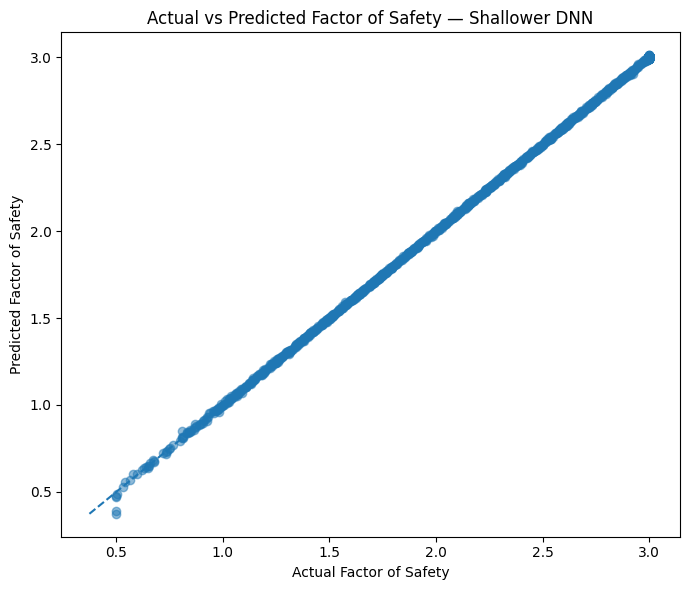

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

actual = np.asarray(y_test)
predicted = np.asarray(y_pred_shallow)

plt.figure(figsize=(7, 6))

plt.scatter(actual, predicted, alpha=0.5)

# Ideal prediction line
minimum = min(actual.min(), predicted.min())
maximum = max(actual.max(), predicted.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle="--"
)

plt.xlabel("Actual Factor of Safety")
plt.ylabel("Predicted Factor of Safety")
plt.title("Actual vs Predicted Factor of Safety — Shallower DNN")
plt.tight_layout()
plt.show()


Factor of Safety Distribution
-----------------------------
Total samples: 10000
Minimum FS: 0.5
Maximum FS: 3.0
Mean FS: 2.54508
Median FS: 3.0

Number of samples with FS = 3.0: 5635
Percentage with FS = 3.0: 56.35 %
Number of unstable samples (FS < 1): 295


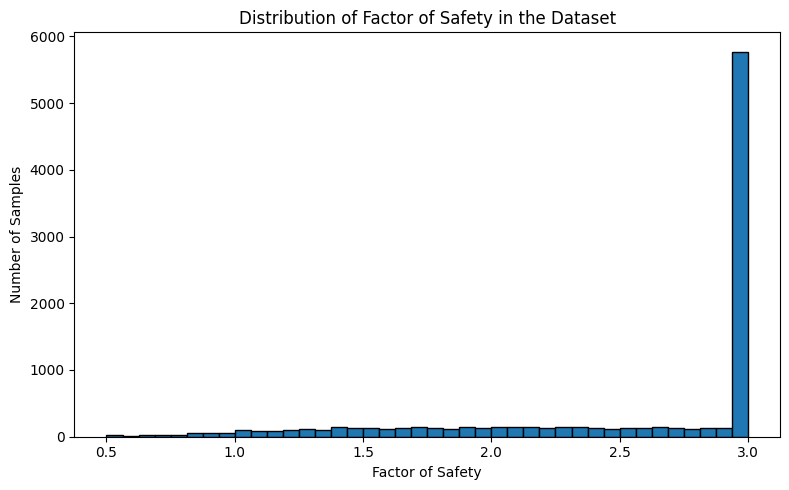

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset
df = pd.read_csv("slope_stability_dataset.csv")

# Basic statistics of Factor of Safety
fs = df["Factor of Safety (FS)"]

print("Factor of Safety Distribution")
print("-----------------------------")
print("Total samples:", len(fs))
print("Minimum FS:", fs.min())
print("Maximum FS:", fs.max())
print("Mean FS:", round(fs.mean(), 5))
print("Median FS:", round(fs.median(), 5))

print("\nNumber of samples with FS = 3.0:",
      (fs == 3.0).sum())

print("Percentage with FS = 3.0:",
      round((fs == 3.0).mean() * 100, 2), "%")

print("Number of unstable samples (FS < 1):",
      (fs < 1).sum())

# Plot the distribution
plt.figure(figsize=(8, 5))
plt.hist(fs, bins=40, edgecolor="black")
plt.xlabel("Factor of Safety")
plt.ylabel("Number of Samples")
plt.title("Distribution of Factor of Safety in the Dataset")
plt.tight_layout()
plt.show()


In [ ]:

import pandas as pd
import numpy as np

df = pd.read_csv("slope_stability_dataset.csv")

fs = df["Factor of Safety (FS)"]

groups = {
    "Unstable (FS < 1)": fs < 1,
    "Stable below 3 (1 <= FS < 3)": (fs >= 1) & (fs < 3),
    "At upper value (FS = 3)": fs == 3
}

rows = []

for name, mask in groups.items():
    values = fs[mask]

    rows.append({
        "Group": name,
        "Samples": len(values),
        "Percentage": len(values) / len(df) * 100,
        "Minimum FS": values.min(),
        "Maximum FS": values.max(),
        "Mean FS": values.mean()
    })

summary = pd.DataFrame(rows)

print(summary.round(4).to_string(index=False))


                       Group  Samples  Percentage  Minimum FS  Maximum FS  Mean FS
           Unstable (FS < 1)      295        2.95      0.5000      0.9989   0.8080
Stable below 3 (1 <= FS < 3)     4070       40.70      1.0003      2.9994   2.0411
     At upper value (FS = 3)     5635       56.35      3.0000      3.0000   3.0000


In [ ]:

import pandas as pd

df = pd.read_csv("slope_stability_dataset.csv")

# Create target groups
df["FS Group"] = df["Factor of Safety (FS)"].apply(
    lambda value: "FS = 3.0" if value == 3.0 else "FS < 3.0"
)

# 1. Count samples by reinforcement type and FS group
print("FS Distribution by Reinforcement Type")
print(
    pd.crosstab(
        df["Reinforcement Type"],
        df["FS Group"],
        margins=True
    ).to_string()
)

# 2. Compare input-property averages
numeric_features = [
    "Unit Weight (kN/m³)",
    "Cohesion (kPa)",
    "Internal Friction Angle (°)",
    "Slope Angle (°)",
    "Slope Height (m)",
    "Pore Water Pressure Ratio"
]

print("\nMean Input Properties by FS Group")
print(
    df.groupby("FS Group")[numeric_features]
      .mean()
      .round(3)
      .to_string()
)

# 3. Compare the proportions at FS = 3.0
print("\nPercentage with FS = 3.0 by Reinforcement Type")
print(
    (df.assign(Is_FS_3=df["Factor of Safety (FS)"] == 3.0)
       .groupby("Reinforcement Type")["Is_FS_3"]
       .mean() * 100)
      .round(2)
      .to_string()
)


FS Distribution by Reinforcement Type
FS Group            FS < 3.0  FS = 3.0    All
Reinforcement Type                           
Drainage                1119      1390   2509
Geosynthetics           1073      1369   2442
Retaining Wall          1109      1408   2517
Soil Nailing            1064      1468   2532
All                     4365      5635  10000

Mean Input Properties by FS Group
          Unit Weight (kN/m³)  Cohesion (kPa)  Internal Friction Angle (°)  Slope Angle (°)  Slope Height (m)  Pore Water Pressure Ratio
FS Group                                                                                                                                
FS < 3.0               19.952          15.259                       31.725           36.408            27.611                      0.523
FS = 3.0               19.934          37.344                       33.103           33.795            27.164                      0.487

Percentage with FS = 3.0 by Reinforcement Type
Reinforce

In [ ]:

import pandas as pd

df = pd.read_csv("slope_stability_dataset.csv")
fs = df["Factor of Safety (FS)"]

print("Values near the upper end of FS")
print("--------------------------------")

for threshold in [2.5, 2.8, 2.9, 2.95, 2.99, 3.0]:
    count = (fs >= threshold).sum()
    percentage = count / len(fs) * 100

    print(
        "FS >=", threshold,
        "| Samples:", count,
        "| Percentage:", round(percentage, 2), "%"
    )

print("\nMost frequent exact FS values")
print(fs.value_counts().head(10).to_string())


Values near the upper end of FS
--------------------------------
FS >= 2.5 | Samples: 6693 | Percentage: 66.93 %
FS >= 2.8 | Samples: 6046 | Percentage: 60.46 %
FS >= 2.9 | Samples: 5862 | Percentage: 58.62 %
FS >= 2.95 | Samples: 5748 | Percentage: 57.48 %
FS >= 2.99 | Samples: 5667 | Percentage: 56.67 %
FS >= 3.0 | Samples: 5635 | Percentage: 56.35 %

Most frequent exact FS values
Factor of Safety (FS)
3.000000    5635
0.500000      13
2.960807       1
1.414603       1
1.357672       1
2.917073       1
1.381975       1
1.742827       1
2.187722       1
2.362792       1


                     Metric     Value
              Mean Residual -0.001139
        Mean Absolute Error  0.003362
    Root Mean Squared Error  0.005543
     Maximum Absolute Error  0.126436
Residual Standard Deviation  0.005425


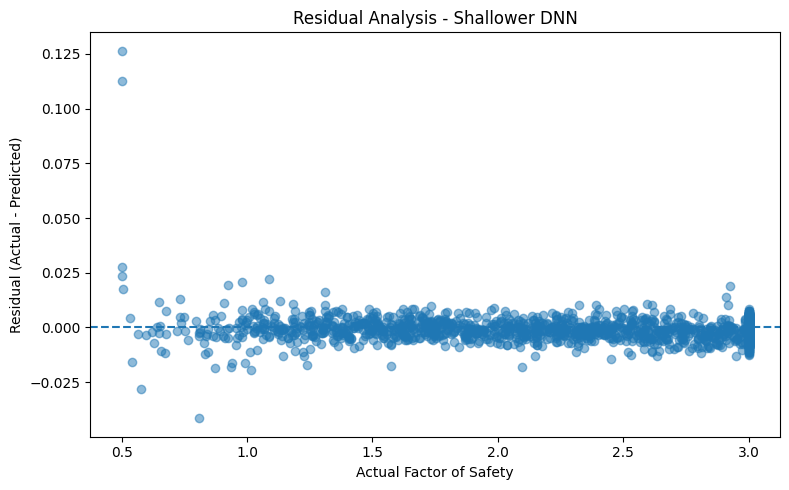

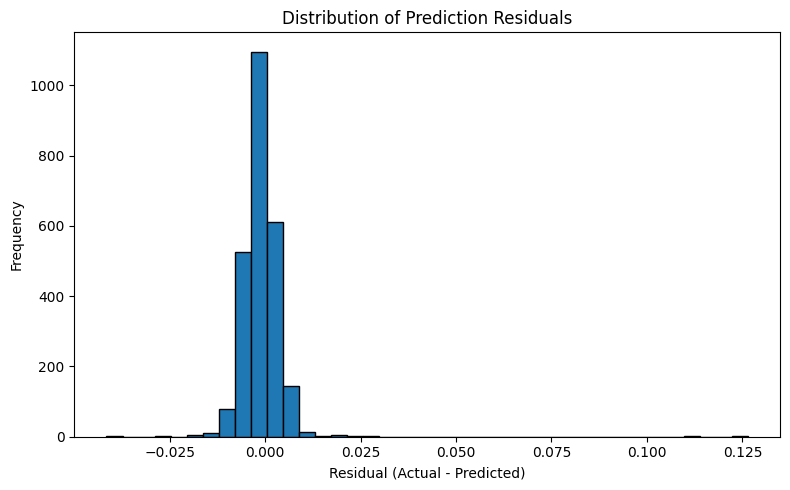

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Calculate prediction errors
actual = np.asarray(y_test).ravel()
predicted = np.asarray(y_pred_shallow).ravel()
residuals = actual - predicted

residual_summary = pd.DataFrame({
    "Metric": [
        "Mean Residual",
        "Mean Absolute Error",
        "Root Mean Squared Error",
        "Maximum Absolute Error",
        "Residual Standard Deviation"
    ],
    "Value": [
        np.mean(residuals),
        mean_absolute_error(actual, predicted),
        np.sqrt(mean_squared_error(actual, predicted)),
        np.max(np.abs(residuals)),
        np.std(residuals)
    ]
})

print(residual_summary.round(6).to_string(index=False))

# Residuals versus actual Factor of Safety
plt.figure(figsize=(8, 5))
plt.scatter(actual, residuals, alpha=0.5)
plt.axhline(y=0, linestyle="--")
plt.xlabel("Actual Factor of Safety")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Analysis - Shallower DNN")
plt.tight_layout()
plt.show()

# Distribution of residuals
plt.figure(figsize=(8, 5))
plt.hist(residuals, bins=40, edgecolor="black")
plt.xlabel("Residual (Actual - Predicted)")
plt.ylabel("Frequency")
plt.title("Distribution of Prediction Residuals")
plt.tight_layout()
plt.show()


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, make_scorer

# Permutation importance for the trained shallower DNN
def dnn_predict(model, data):
    return model.predict(
        np.asarray(data, dtype=np.float32), verbose=0
    ).ravel()

def dnn_neg_mse(model, X, y):
    predictions = dnn_predict(model, X)
    return -mean_squared_error(y, predictions)

# Use the existing scaled test data and trained model
perm_results = permutation_importance(
    estimator=shallow_dnn,
    X=X_test.astype(np.float32),
    y=y_test,
    scoring=dnn_neg_mse,
    n_repeats=10,
    random_state=42,
    n_jobs=1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm_results.importances_mean,
    "Standard Deviation": perm_results.importances_std
})

importance_df = importance_df.sort_values(
    by="Importance", ascending=False
)

print(importance_df.round(6).to_string(index=False))

# Plot the feature importance values
plt.figure(figsize=(9, 6))
plt.barh(
    importance_df["Feature"],
    importance_df["Importance"],
    xerr=importance_df["Standard Deviation"]
)
plt.gca().invert_yaxis()
plt.xlabel("Increase in MSE after permutation")
plt.ylabel("Input Feature")
plt.title("Permutation Feature Importance - Shallower DNN")
plt.tight_layout()
plt.show()


NameError: name 'shallow_dnn' is not defined

In [ ]:

print("shallow_dnn exists:", "shallow_dnn" in globals())
print("y_pred_shallow exists:", "y_pred_shallow" in globals())
print("X_test exists:", "X_test" in globals())
print("y_test exists:", "y_test" in globals())
print("shallow model alternative exists:", "dnn" in globals())


shallow_dnn exists: False
y_pred_shallow exists: False
X_test exists: False
y_test exists: False
shallow model alternative exists: False


In [ ]:

import os

print("Current working directory:")
print(os.getcwd())

print("\nSaved model and scaler files:")

for root, dirs, files in os.walk("."):
    dirs[:] = [
        d for d in dirs
        if d not in [".git", "__pycache__"]
    ]

    for file in files:
        if (
            file.endswith((".keras", ".h5", ".joblib", ".pkl"))
            and (
                "model" in file.lower()
                or "dnn" in file.lower()
                or "scaler" in file.lower()
            )
        ):
            print(os.path.join(root, file))


Current working directory:
/content

Saved model and scaler files:


In [ ]:

import os
import joblib
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow import keras
from tensorflow.keras import layers

# Find the dataset
if os.path.exists("slope_stability_dataset.csv"):
    csv_file = "slope_stability_dataset.csv"
elif os.path.exists("slope_stability_dataset(1).csv"):
    csv_file = "slope_stability_dataset(1).csv"
else:
    raise FileNotFoundError(
        "Upload slope_stability_dataset.csv to Colab first."
    )

df = pd.read_csv(csv_file)

feature_columns = [
    "Unit Weight (kN/m³)",
    "Cohesion (kPa)",
    "Internal Friction Angle (°)",
    "Slope Angle (°)",
    "Slope Height (m)",
    "Pore Water Pressure Ratio",
    "Reinforcement Type"
]

numeric_columns = feature_columns[:-1]
X = pd.get_dummies(
    df[feature_columns].copy(),
    columns=["Reinforcement Type"],
    dtype=int
)
y = df["Factor of Safety (FS)"]

# Preserve the original 75:25 split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

# Fit scaler on training data only
scaler = StandardScaler()
X_train = X_train.copy()
X_test = X_test.copy()

X_train.loc[:, numeric_columns] = scaler.fit_transform(
    X_train[numeric_columns]
)
X_test.loc[:, numeric_columns] = scaler.transform(
    X_test[numeric_columns]
)

# Train only the previously selected shallower DNN
tf.keras.utils.set_random_seed(42)

shallow_dnn = keras.Sequential([
    keras.Input(shape=(X_train.shape[1],)),
    layers.Dense(32, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(1)
])

shallow_dnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True
)

history = shallow_dnn.fit(
    X_train.astype("float32"),
    y_train.astype("float32"),
    validation_split=0.2,
    epochs=200,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

y_pred_shallow = shallow_dnn.predict(
    X_test.astype("float32"), verbose=0
).ravel()

# Save model and preprocessing
shallow_dnn.save("shallow_dnn.keras")
joblib.dump(scaler, "scaler.joblib")

print("\nTraining complete.")
print("Training samples:", len(X_train))
print("Test samples:", len(X_test))
print("Epochs completed:", len(history.history["loss"]))
print("Model and scaler saved.")


FileNotFoundError: Upload slope_stability_dataset.csv to Colab first.

In [ ]:

from google.colab import files

uploaded = files.upload()

print("Uploaded files:", list(uploaded.keys()))


Saving slope_stability_dataset.csv to slope_stability_dataset.csv
Uploaded files: ['slope_stability_dataset.csv']


In [ ]:

import os

print("CSV files available:")
for file in os.listdir("/content"):
    if file.lower().endswith(".csv"):
        print(file)


CSV files available:
slope_stability_dataset.csv


In [ ]:

import os

for root, dirs, files_list in os.walk("/content"):
    for file in files_list:
        if file.lower().endswith(".csv"):
            print(os.path.join(root, file))


/content/slope_stability_dataset.csv
/content/sample_data/california_housing_test.csv
/content/sample_data/mnist_train_small.csv
/content/sample_data/california_housing_train.csv
/content/sample_data/mnist_test.csv


In [ ]:

csv_file = "/content/slope_stability_dataset.csv"
df = pd.read_csv(csv_file)

print("Dataset loaded:", df.shape)
print("Columns:", df.columns.tolist())


Dataset loaded: (10000, 9)
Columns: ['Unit Weight (kN/m³)', 'Cohesion (kPa)', 'Internal Friction Angle (°)', 'Slope Angle (°)', 'Slope Height (m)', 'Pore Water Pressure Ratio', 'Reinforcement Type', 'Reinforcement Numeric', 'Factor of Safety (FS)']


In [ ]:
csv_file = "/content/slope_stability_dataset.csv"

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error

# Permutation importance for the restored shallower DNN
def dnn_neg_mse(model, X, y):
    predictions = model.predict(
        np.asarray(X, dtype=np.float32),
        verbose=0
    ).ravel()
    return -mean_squared_error(y, predictions)

perm_results = permutation_importance(
    estimator=shallow_dnn,
    X=X_test.astype(np.float32),
    y=y_test,
    scoring=dnn_neg_mse,
    n_repeats=10,
    random_state=42,
    n_jobs=1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm_results.importances_mean,
    "Standard Deviation": perm_results.importances_std
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df.round(6).to_string(index=False))

plt.figure(figsize=(9, 6))
plt.barh(
    importance_df["Feature"],
    importance_df["Importance"],
    xerr=importance_df["Standard Deviation"]
)
plt.gca().invert_yaxis()
plt.axvline(x=0, linestyle="--")
plt.xlabel("Increase in MSE after permutation")
plt.ylabel("Feature")
plt.title("Permutation Feature Importance - Shallower DNN")
plt.tight_layout()
plt.show()


NameError: name 'shallow_dnn' is not defined

In [ ]:

variables_to_check = [
    "shallow_dnn",
    "X_test",
    "y_test",
    "scaler",
    "y_pred_shallow",
    "importance_df"
]

for variable in variables_to_check:
    print(variable, ":", variable in globals())

import os

print("\nSaved model exists:", os.path.exists("/content/shallow_dnn.keras"))
print("Saved scaler exists:", os.path.exists("/content/scaler.joblib"))


shallow_dnn : False
X_test : False
y_test : False
scaler : False
y_pred_shallow : False
importance_df : False

Saved model exists: False
Saved scaler exists: False


In [ ]:

import os
import joblib
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Load the existing dataset
df = pd.read_csv("/content/slope_stability_dataset.csv")

feature_columns = [
    "Unit Weight (kN/m³)",
    "Cohesion (kPa)",
    "Internal Friction Angle (°)",
    "Slope Angle (°)",
    "Slope Height (m)",
    "Pore Water Pressure Ratio",
    "Reinforcement Type"
]

numeric_columns = feature_columns[:-1]

X = pd.get_dummies(
    df[feature_columns].copy(),
    columns=["Reinforcement Type"],
    dtype=int
)
y = df["Factor of Safety (FS)"]

# Keep the existing 75:25 split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

# Standardize numerical features
scaler = StandardScaler()
X_train = X_train.copy()
X_test = X_test.copy()

X_train.loc[:, numeric_columns] = scaler.fit_transform(
    X_train[numeric_columns]
)
X_test.loc[:, numeric_columns] = scaler.transform(
    X_test[numeric_columns]
)

# Train the selected shallower DNN only
tf.keras.utils.set_random_seed(42)

shallow_dnn = keras.Sequential([
    keras.Input(shape=(X_train.shape[1],)),
    layers.Dense(32, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(1)
])

shallow_dnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True
)

history = shallow_dnn.fit(
    X_train.astype("float32"),
    y_train.astype("float32"),
    validation_split=0.2,
    epochs=200,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

y_pred_shallow = shallow_dnn.predict(
    X_test.astype("float32"), verbose=0
).ravel()

# Save artifacts
shallow_dnn.save("/content/shallow_dnn.keras")
joblib.dump(scaler, "/content/scaler.joblib")

print("\nModel restored and saved.")
print("Training samples:", len(X_train))
print("Test samples:", len(X_test))
print("Epochs completed:", len(history.history["loss"]))
print("Model file exists:", os.path.exists("/content/shallow_dnn.keras"))
print("Scaler file exists:", os.path.exists("/content/scaler.joblib"))


Epoch 1/200
188/188 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - loss: 2.3356 - mae: 1.2035 - val_loss: 0.3448 - val_mae: 0.4804
Epoch 2/200
188/188 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.2472 - mae: 0.4018 - val_loss: 0.1905 - val_mae: 0.3609
Epoch 3/200
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.1362 - mae: 0.2984 - val_loss: 0.0921 - val_mae: 0.2491
Epoch 4/200
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0594 - mae: 0.1929 - val_loss: 0.0377 - val_mae: 0.1557
Epoch 5/200
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0294 - mae: 0.1361 - val_loss: 0.0215 - val_mae: 0.1183
Epoch 6/200
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0180 - mae: 0.1066 - val_loss: 0.0139 - val_mae: 0.0947
Epoch 7/200
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0121 - mae: 0.0871 - val_loss: 0.0099 - val_mae: 0.0793
Epoch 8/200
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0087 - mae: 0.0738 - val_loss: 0.0075 - val_mae: 0.0683
Epoch 9/200
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms

                          Feature  Importance  Standard Deviation
                   Cohesion (kPa)    0.828843            0.016997
Reinforcement Type_Retaining Wall    0.640176            0.014106
      Reinforcement Type_Drainage    0.631781            0.006970
  Reinforcement Type_Soil Nailing    0.627906            0.011572
 Reinforcement Type_Geosynthetics    0.589124            0.012079
      Internal Friction Angle (°)    0.048043            0.001282
        Pore Water Pressure Ratio    0.017623            0.000562
                  Slope Angle (°)    0.017386            0.000653
              Unit Weight (kN/m³)    0.000003            0.000004
                 Slope Height (m)   -0.000001            0.000001


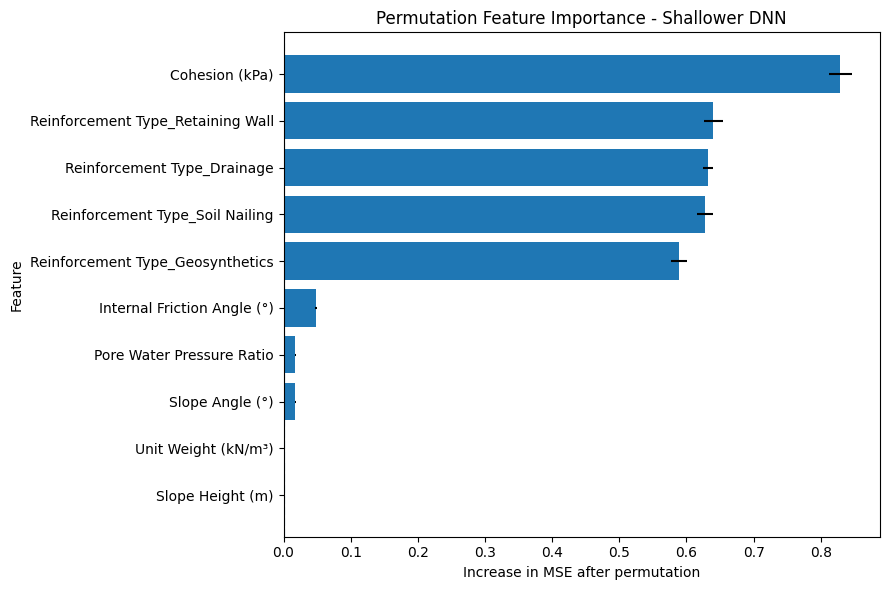

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error

def dnn_neg_mse(model, X, y):
    predictions = model.predict(
        np.asarray(X, dtype=np.float32),
        verbose=0
    ).ravel()
    return -mean_squared_error(y, predictions)

perm_results = permutation_importance(
    estimator=shallow_dnn,
    X=X_test.astype(np.float32),
    y=y_test,
    scoring=dnn_neg_mse,
    n_repeats=10,
    random_state=42,
    n_jobs=1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm_results.importances_mean,
    "Standard Deviation": perm_results.importances_std
})

importance_df = importance_df.sort_values(
    "Importance", ascending=False
)

print(importance_df.round(6).to_string(index=False))

plt.figure(figsize=(9, 6))
plt.barh(
    importance_df["Feature"],
    importance_df["Importance"],
    xerr=importance_df["Standard Deviation"]
)
plt.gca().invert_yaxis()
plt.axvline(x=0, linestyle="--")
plt.xlabel("Increase in MSE after permutation")
plt.ylabel("Feature")
plt.title("Permutation Feature Importance - Shallower DNN")
plt.tight_layout()
plt.show()


In [ ]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_pred_shallow = shallow_dnn.predict(
    X_test.astype(np.float32), verbose=0
).ravel()

actual = np.asarray(y_test).ravel()

mae = mean_absolute_error(actual, y_pred_shallow)
rmse = np.sqrt(mean_squared_error(actual, y_pred_shallow))
r2 = r2_score(actual, y_pred_shallow)

print("Shallower DNN - Final Test Results")
print("---------------------------------")
print("MAE:", round(mae, 6))
print("RMSE:", round(rmse, 6))
print("R2 Score:", round(r2, 6))


Shallower DNN - Final Test Results
---------------------------------
MAE: 0.003362
RMSE: 0.005543
R2 Score: 0.999929


In [ ]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

results = pd.DataFrame({
    "Actual FS": np.asarray(y_test).ravel(),
    "Predicted FS": np.asarray(y_pred_shallow).ravel()
})

results["Absolute Error"] = abs(
    results["Actual FS"] - results["Predicted FS"]
)

results["FS Category"] = np.select(
    [
        results["Actual FS"] < 1,
        results["Actual FS"] < 3
    ],
    [
        "Unstable (FS < 1)",
        "Stable (1 ≤ FS < 3)"
    ],
    default="FS = 3"
)

summary = []

for category, group in results.groupby("FS Category"):
    errors = group["Actual FS"] - group["Predicted FS"]

    summary.append({
        "FS Category": category,
        "Samples": len(group),
        "MAE": mean_absolute_error(
            group["Actual FS"], group["Predicted FS"]
        ),
        "RMSE": np.sqrt(mean_squared_error(
            group["Actual FS"], group["Predicted FS"]
        )),
        "Maximum Absolute Error": errors.abs().max()
    })

summary_df = pd.DataFrame(summary)

print(summary_df.round(6).to_string(index=False))


        FS Category  Samples      MAE     RMSE  Maximum Absolute Error
             FS = 3     1405 0.002899 0.003639                0.012674
Stable (1 ≤ FS < 3)     1023 0.003499 0.004580                0.022292
  Unstable (FS < 1)       72 0.010442 0.022596                0.126436


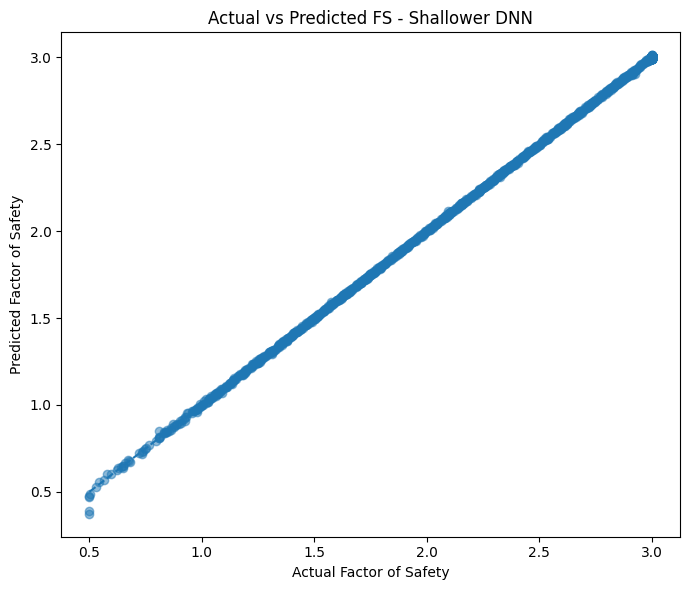

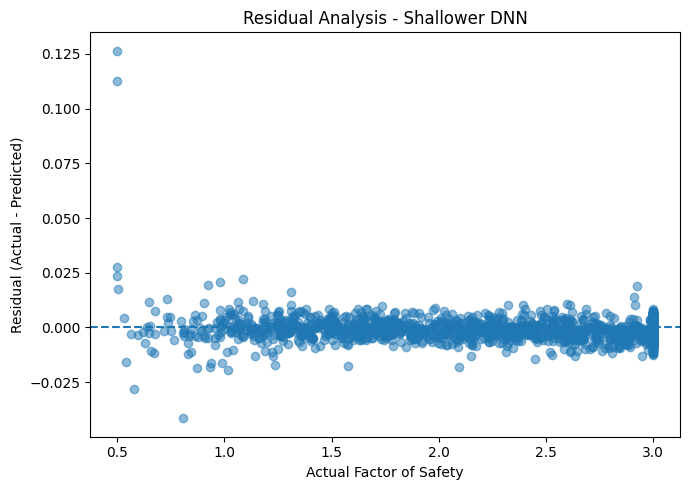

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

actual = np.asarray(y_test).ravel()
predicted = np.asarray(y_pred_shallow).ravel()
residuals = actual - predicted

# Plot 1: Actual vs predicted FS
plt.figure(figsize=(7, 6))
plt.scatter(actual, predicted, alpha=0.5)
plt.plot(
    [actual.min(), actual.max()],
    [actual.min(), actual.max()],
    linestyle="--"
)
plt.xlabel("Actual Factor of Safety")
plt.ylabel("Predicted Factor of Safety")
plt.title("Actual vs Predicted FS - Shallower DNN")
plt.tight_layout()
plt.show()

# Plot 2: Residuals vs actual FS
plt.figure(figsize=(7, 5))
plt.scatter(actual, residuals, alpha=0.5)
plt.axhline(y=0, linestyle="--")
plt.xlabel("Actual Factor of Safety")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Analysis - Shallower DNN")
plt.tight_layout()
plt.show()


In [ ]:

import os
import zipfile
import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

output_dir = "/content/slope_stability_results"
os.makedirs(output_dir, exist_ok=True)

# Save the trained model and fitted scaler
shallow_dnn.save(os.path.join(output_dir, "shallow_dnn.keras"))
joblib.dump(scaler, os.path.join(output_dir, "scaler.joblib"))

# Save actual and predicted test results
actual = np.asarray(y_test).ravel()
predicted = np.asarray(y_pred_shallow).ravel()

predictions_df = pd.DataFrame({
    "Actual_FS": actual,
    "Predicted_FS": predicted,
    "Residual": actual - predicted,
    "Absolute_Error": np.abs(actual - predicted)
})
predictions_df.to_csv(
    os.path.join(output_dir, "test_predictions.csv"), index=False
)

# Save current model metrics
metrics_df = pd.DataFrame([{
    "Model": "Shallower DNN (32-16)",
    "MAE": mean_absolute_error(actual, predicted),
    "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
    "R2": r2_score(actual, predicted)
}])
metrics_df.to_csv(
    os.path.join(output_dir, "shallow_dnn_metrics.csv"), index=False
)

# Save feature importance if already calculated
if "importance_df" in globals():
    importance_df.to_csv(
        os.path.join(output_dir, "permutation_feature_importance.csv"),
        index=False
    )

# Save training history if available
if "history" in globals():
    pd.DataFrame(history.history).to_csv(
        os.path.join(output_dir, "training_history.csv"), index=False
    )

# Bundle all saved results
zip_path = "/content/slope_stability_results.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for filename in os.listdir(output_dir):
        archive.write(
            os.path.join(output_dir, filename),
            arcname=filename
        )

print("Saved model, scaler, predictions and available results.")
print("Results folder:", output_dir)
print("ZIP archive:", zip_path)
print("\nFinal DNN metrics:")
print(metrics_df.round(6).to_string(index=False))


Saved model, scaler, predictions and available results.
Results folder: /content/slope_stability_results
ZIP archive: /content/slope_stability_results.zip

Final DNN metrics:
                Model      MAE     RMSE       R2
Shallower DNN (32-16) 0.003362 0.005543 0.999929


In [ ]:

unstable = predictions_df[predictions_df["Actual_FS"] < 1].copy()

unstable["Overprediction"] = (
    unstable["Predicted_FS"] - unstable["Actual_FS"]
)

print("Number of unstable test samples:", len(unstable))
print(
    "Cases with overpredicted FS:",
    (unstable["Overprediction"] > 0).sum()
)
print(
    "Cases predicted as FS >= 1:",
    (unstable["Predicted_FS"] >= 1).sum()
)

print("\nLargest overpredictions for unstable samples:")
print(
    unstable.sort_values("Overprediction", ascending=False)
    .head(10)
    .round(5)
    .to_string(index=False)
)


Number of unstable test samples: 72
Cases with overpredicted FS: 43
Cases predicted as FS >= 1: 1

Largest overpredictions for unstable samples:
 Actual_FS  Predicted_FS  Residual  Absolute_Error  Overprediction
   0.80863       0.85015  -0.04151         0.04151         0.04151
   0.57679       0.60480  -0.02801         0.02801         0.02801
   0.87041       0.88906  -0.01865         0.01865         0.01865
   0.93545       0.95373  -0.01828         0.01828         0.01828
   0.93819       0.95431  -0.01613         0.01613         0.01613
   0.99026       1.00636  -0.01609         0.01609         0.01609
   0.54231       0.55826  -0.01594         0.01594         0.01594
   0.83192       0.84388  -0.01195         0.01195         0.01195
   0.67140       0.68320  -0.01179         0.01179         0.01179
   0.84626       0.85748  -0.01122         0.01122         0.01122


In [ ]:

threshold_case = unstable[unstable["Predicted_FS"] >= 1]

print("Unstable samples predicted as FS >= 1:")
print(threshold_case.round(6).to_string(index=False))


Unstable samples predicted as FS >= 1:
 Actual_FS  Predicted_FS  Residual  Absolute_Error  Overprediction
  0.990261      1.006355 -0.016094        0.016094        0.016094


In [ ]:

%pip install shap


In [ ]:

import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Small samples to keep KernelExplainer computationally manageable
background = shap.sample(X_train, 30, random_state=42)
explain_data = shap.sample(X_test, 50, random_state=42)

def predict_fs(data):
    data = np.asarray(data, dtype=np.float32)
    return shallow_dnn.predict(data, verbose=0).ravel()

explainer = shap.KernelExplainer(
    predict_fs,
    background
)

shap_values = explainer.shap_values(
    explain_data,
    nsamples=100
)

# Handle output shape consistently
shap_array = np.asarray(shap_values)
if shap_array.ndim == 3:
    shap_array = shap_array[0]

print("SHAP values shape:", shap_array.shape)
print("Explained samples:", len(explain_data))
print("Features:", len(X_test.columns))


  0%|          | 0/50 [00:00<?, ?it/s]

SHAP values shape: (50, 10)
Explained samples: 50
Features: 10


/tmp/ipykernel_574/758745353.py:2: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


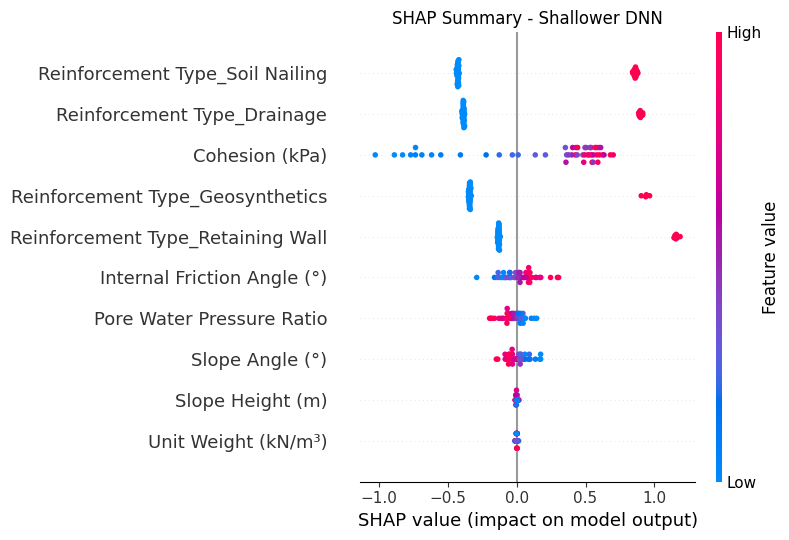

                          Feature  Mean Absolute SHAP
  Reinforcement Type_Soil Nailing            0.600659
      Reinforcement Type_Drainage            0.540397
                   Cohesion (kPa)            0.510631
 Reinforcement Type_Geosynthetics            0.401162
Reinforcement Type_Retaining Wall            0.336901
      Internal Friction Angle (°)            0.090607
        Pore Water Pressure Ratio            0.058902
                  Slope Angle (°)            0.057491
                 Slope Height (m)            0.004484
              Unit Weight (kN/m³)            0.003476


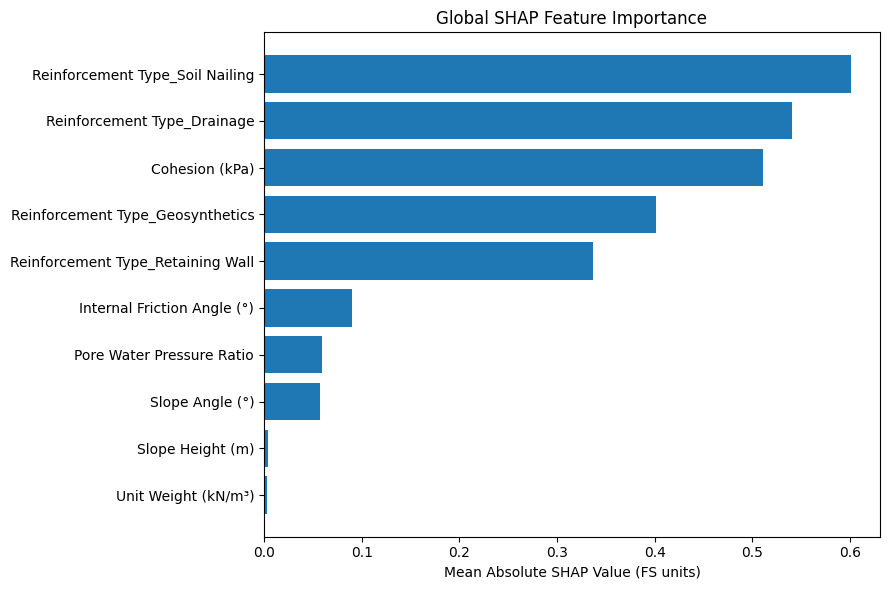

In [ ]:

# Global SHAP summary plot
shap.summary_plot(
    shap_array,
    explain_data,
    feature_names=list(X_test.columns),
    show=False
)
plt.title("SHAP Summary - Shallower DNN")
plt.tight_layout()
plt.show()

# Mean absolute SHAP importance
shap_importance = pd.DataFrame({
    "Feature": list(X_test.columns),
    "Mean Absolute SHAP": np.abs(shap_array).mean(axis=0)
}).sort_values("Mean Absolute SHAP", ascending=False)

print(shap_importance.round(6).to_string(index=False))

plt.figure(figsize=(9, 6))
plt.barh(
    shap_importance["Feature"],
    shap_importance["Mean Absolute SHAP"]
)
plt.gca().invert_yaxis()
plt.xlabel("Mean Absolute SHAP Value (FS units)")
plt.title("Global SHAP Feature Importance")
plt.tight_layout()
plt.show()
